# 700_CNN — classification des utilisateurs avec un CNN

Ce notebook construit une première expérience complète de classification à partir des tableaux préparés dans `data/processed/1clean/`.

**Important pour l’évaluation :** `cleaned_test.csv` ne contient pas la colonne `util`. Il est donc impossible d’y calculer la précision, le rappel ou le F1-score. Ces métriques seront calculées sur une validation interne stratifiée tirée de `cleaned_train.csv`. Le test sera utilisé uniquement pour générer des prédictions.

Les entrées sont des caractéristiques tabulaires agrégées (compteurs d’actions, d’écrans, de chaînes, navigateur, etc.), pas une séquence temporelle. Un CNN 1D sur les colonnes est donc **expérimental** : l’ordre des colonnes ne représente pas le temps. La sélection des caractéristiques est apprise sur les données d’entraînement de chaque étape afin d’éviter la fuite de cible.

## 1. Configuration et imports

Les paramètres modifiables de l’expérience sont regroupés dans la cellule suivante. Si TensorFlow/Keras ou scikit-learn manque dans le noyau choisi, installez les dépendances dans cet environnement avant de poursuivre.

In [1]:
from pathlib import Path
import os
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
TEST_SIZE = 0.20          # part de train réservée à l'évaluation finale
STOP_SIZE = 0.15          # part interne pour l'arrêt anticipé
TOP_K = 128               # nombre maximum de variables sélectionnées
MAX_EPOCHS = 100
BATCH_SIZE = 64
LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)
print("GPU(s):", tf.config.list_physical_devices("GPU"))

/Users/macairm1/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow: 2.20.0
GPU(s): []


## 2. Repérer le dépôt et charger les fichiers `1clean`

La recherche du dossier fonctionne si le notebook est lancé depuis la racine du dépôt ou depuis `Notebooks/`. Les colonnes caractéristiques sont alignées entre train et test; l'identifiant `util` est conservé séparément comme cible.

In [2]:
def find_project_root(start: Path) -> Path:
    """Find the repository root containing the requested 1clean directory."""
    for candidate in (start, *start.parents):
        expected = candidate / "data" / "processed" / "1clean"
        if expected.is_dir():
            return candidate
    raise FileNotFoundError(
        "Impossible de trouver data/processed/1clean. "
        "Placez le notebook dans le dépôt et vérifiez les fichiers de données."
    )

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "1clean"
TRAIN_PATH = DATA_DIR / "cleaned_train.csv"
TEST_PATH = DATA_DIR / "cleaned_test.csv"

if not TRAIN_PATH.is_file() or not TEST_PATH.is_file():
    raise FileNotFoundError(f"Fichier train ou test absent dans {DATA_DIR}")

train_df = pd.read_csv(TRAIN_PATH, low_memory=False)
test_df = pd.read_csv(TEST_PATH, low_memory=False)
TARGET = "util"

if TARGET not in train_df.columns:
    raise ValueError(f"La cible {TARGET!r} manque dans le fichier train.")
if TARGET in test_df.columns:
    raise ValueError("Le fichier test contient util; vérifier le schéma attendu.")

y_text = train_df[TARGET].astype(str)
X_all_df = train_df.drop(columns=[TARGET]).copy()
X_test_df = test_df.copy()

# Retirer le doublon déjà observé dans 1clean; les deux colonnes désignent ici la même valeur.
if "duration_seconds" in X_all_df and "max_time" in X_all_df:
    if not X_all_df["duration_seconds"].equals(X_all_df["max_time"]):
        warnings.warn("duration_seconds diffère de max_time; les deux variables sont conservées.")
    else:
        X_all_df = X_all_df.drop(columns=["duration_seconds"])
        X_test_df = X_test_df.drop(columns=["duration_seconds"])

if list(X_all_df.columns) != list(X_test_df.columns):
    raise ValueError("Les colonnes de caractéristiques du train et du test ne correspondent pas.")
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_all_df.dtypes):
    raise TypeError("Toutes les caractéristiques doivent être numériques.")
if X_all_df.isna().any().any() or X_test_df.isna().any().any():
    raise ValueError("Des valeurs manquantes sont présentes; inspectez-les avant le modèle.")

print("Racine du projet:", PROJECT_ROOT)
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Utilisateurs:", y_text.nunique(), "| Variables brutes:", X_all_df.shape[1])
print("Valeurs manquantes train/test:", int(X_all_df.isna().sum().sum()), int(X_test_df.isna().sum().sum()))
display(train_df.head())

Racine du projet: /Users/macairm1/Desktop/3AECLM2/BE/ML & DS/BE_MachineLearning
Train: (3279, 766) | Test: (324, 765)
Utilisateurs: 247 | Variables brutes: 764
Valeurs manquantes train/test: 0 0


,util,n_tokens,n_actions,n_time_markers,max_time,duration_seconds,n_distinct_verbs,n_screens,n_distinct_screens,n_configs,...,screen__infologic.ventes.modules.VT_DEVIS_CONTRAT.home.DevisAccueilHomeView,screen__infologic.ventes.modules.VT_FACTURATION.EditFactureForm,screen__infologic.ventes.modules.VT_FACTURATION.FactureVteForm,screen__infologic.ventes.modules.VT_LIVRAISON.EditBonLivForm,screen__infologic.ventes.modules.VT_LIVRAISON.LivraisonForm,screen__infologic.ventes.modules.VT_LIVRAISON.ReeditBonLivParamActionForm,screen__infologic.ventes.modules.VT_TARIFICATION.TarBaseVTForm,screen__smsi_fournisseurs,screen__smsi_fournisseurs_contrats,screen__smsi_fournisseurs_services
0,nuh,3128,2514,614,2905,2905,19,191,7,7,...,0,0,0,0,0,0,0,0,0,0
1,muz,136,90,46,230,230,11,8,5,4,...,0,0,0,0,0,0,0,0,0,0
2,zrx,766,608,158,750,750,21,94,17,35,...,0,0,0,0,0,0,0,0,0,0
3,pou,1199,886,313,1445,1445,19,249,10,9,...,0,0,0,0,0,0,0,0,0,0
4,ald,233,173,60,275,275,14,21,8,7,...,0,0,0,0,0,0,0,0,0,0


## 3. Exploration des données

On vérifie la distribution de la cible, les types et les variables numériques. Les graphiques de classes affichent les utilisateurs les plus représentés; les effectifs complets restent disponibles dans `class_counts`.

3,279 sessions train | 324 sessions test
247 utilisateurs | min=4 | médiane=12 | max=75
Lignes dupliquées train: 0


,nombre de colonnes
int64,765
object,1


,util,sessions
0,skm,75
1,slq,71
2,cjr,46
3,flj,42
4,hjs,37
5,vfo,35
6,shh,34
7,nqg,34
8,fwf,33
9,kwi,31


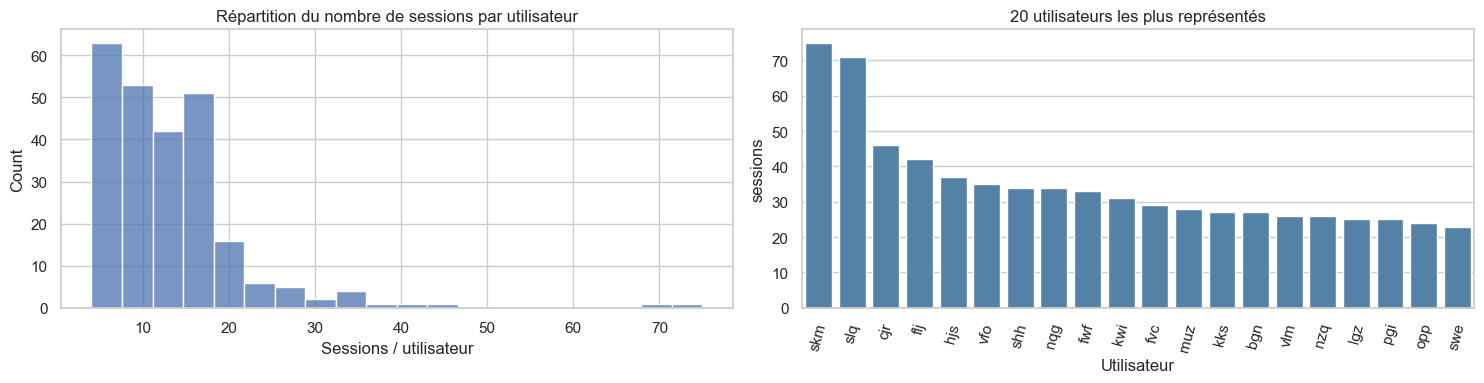

,sessions
browser__Firefox,1466
browser__Google Chrome,1339
browser__Microsoft Edge,451
browser__Opera,23


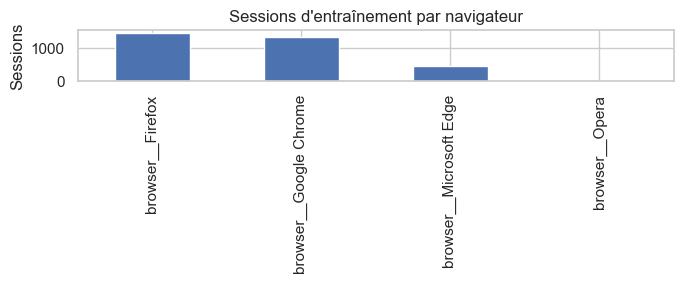

In [3]:
class_counts = y_text.value_counts().rename_axis("util").reset_index(name="sessions")
print(f"{len(train_df):,} sessions train | {len(test_df):,} sessions test")
print(f"{y_text.nunique()} utilisateurs | min={class_counts.sessions.min()} | médiane={class_counts.sessions.median():.0f} | max={class_counts.sessions.max()}")
print("Lignes dupliquées train:", int(train_df.duplicated().sum()))
display(train_df.dtypes.astype(str).value_counts().rename("nombre de colonnes").to_frame())
display(class_counts.head(15))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(class_counts["sessions"], bins=20, ax=axes[0])
axes[0].set(title="Répartition du nombre de sessions par utilisateur", xlabel="Sessions / utilisateur")
sns.barplot(data=class_counts.head(20), x="util", y="sessions", ax=axes[1], color="steelblue")
axes[1].tick_params(axis="x", rotation=75)
axes[1].set(title="20 utilisateurs les plus représentés", xlabel="Utilisateur")
plt.tight_layout()
plt.show()

browser_columns = [column for column in X_all_df if column.startswith("browser__")]
if browser_columns:
    browser_counts = X_all_df[browser_columns].sum().sort_values(ascending=False)
    display(browser_counts.rename("sessions").to_frame())
    browser_counts.plot(kind="bar", figsize=(7, 3), title="Sessions d'entraînement par navigateur")
    plt.ylabel("Sessions")
    plt.tight_layout()
    plt.show()

## 4. Séparation train / arrêt anticipé / validation finale

La validation finale est mise de côté et ne sert ni à sélectionner les variables, ni à arrêter l'entraînement. Une seconde séparation stratifiée dans le sous-ensemble de développement sert seulement à l'arrêt anticipé. La stratification préserve au mieux les utilisateurs dans ces petits ensembles; certaines classes n'ont toutefois que quatre exemples, ce qui rend les estimations par classe fragiles.

In [4]:
X_dev_df, X_eval_df, y_dev_text, y_eval_text = train_test_split(
    X_all_df,
    y_text,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_text,
)
X_fit_df, X_stop_df, y_fit_text, y_stop_text = train_test_split(
    X_dev_df,
    y_dev_text,
    test_size=STOP_SIZE,
    random_state=SEED,
    stratify=y_dev_text,
)

label_encoder = LabelEncoder()
label_encoder.fit(y_text)
y_fit = label_encoder.transform(y_fit_text)
y_stop = label_encoder.transform(y_stop_text)
y_eval = label_encoder.transform(y_eval_text)

print("Fit CNN:", len(X_fit_df), "| arrêt anticipé:", len(X_stop_df), "| évaluation finale:", len(X_eval_df))
print("Classes dans le fit:", len(np.unique(y_fit)), "/", len(label_encoder.classes_))
print("La validation finale n'a pas été utilisée dans les étapes de prétraitement ou d'entraînement.")

Fit CNN: 2229 | arrêt anticipé: 394 | évaluation finale: 656
Classes dans le fit: 247 / 247
La validation finale n'a pas été utilisée dans les étapes de prétraitement ou d'entraînement.


## 5. Sélection des variables et mise à l'échelle

`VarianceThreshold` retire les colonnes constantes dans le sous-ensemble de fit. `SelectKBest(f_classif)` classe ensuite les variables par association univariée avec `util` et garde au plus `TOP_K`. Le sélecteur et le scaler sont ajustés **uniquement sur `X_fit_df`**, puis appliqués à l'arrêt anticipé et à l'évaluation. Cela évite que les statistiques de ces lignes influencent la sélection.

In [5]:
variance_filter = VarianceThreshold(threshold=0.0)
X_fit_var = variance_filter.fit_transform(X_fit_df)
X_stop_var = variance_filter.transform(X_stop_df)
X_eval_var = variance_filter.transform(X_eval_df)
X_test_var = variance_filter.transform(X_test_df)
nonconstant_names = X_fit_df.columns[variance_filter.get_support()]
if len(nonconstant_names) == 0:
    raise ValueError("Toutes les caractéristiques sont constantes dans le fit.")

def safe_f_classif(X, y):
    """Compute ANOVA F scores and safely rank infinite scores first."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        f_scores, p_values = f_classif(X, y)
    finite_scores = f_scores[np.isfinite(f_scores)]
    infinite_rank = finite_scores.max() + 1.0 if finite_scores.size else 1.0
    f_scores = np.nan_to_num(f_scores, nan=0.0, posinf=infinite_rank, neginf=0.0)
    return f_scores, p_values

selector = SelectKBest(score_func=safe_f_classif, k=min(TOP_K, len(nonconstant_names)))
X_fit_selected = selector.fit_transform(X_fit_var, y_fit)
X_stop_selected = selector.transform(X_stop_var)
X_eval_selected = selector.transform(X_eval_var)
selected_names = nonconstant_names[selector.get_support()]

scaler = StandardScaler()
X_fit_scaled = scaler.fit_transform(X_fit_selected).astype(np.float32)
X_stop_scaled = scaler.transform(X_stop_selected).astype(np.float32)
X_eval_scaled = scaler.transform(X_eval_selected).astype(np.float32)

scores = selector.scores_
feature_ranking = pd.DataFrame({"caracteristique": nonconstant_names, "score_F": scores})
feature_ranking = feature_ranking.sort_values("score_F", ascending=False)
print(f"Variables constantes retirées: {X_fit_df.shape[1] - len(nonconstant_names)}")
print(f"Variables retenues: {len(selected_names)} / {X_fit_df.shape[1]}")
display(feature_ranking.head(25))

n_features = X_fit_scaled.shape[1]
def as_cnn_input(matrix):
    return matrix.reshape(matrix.shape[0], matrix.shape[1], 1)

X_fit_cnn = as_cnn_input(X_fit_scaled)
X_stop_cnn = as_cnn_input(X_stop_scaled)
X_eval_cnn = as_cnn_input(X_eval_scaled)
print("Forme d'une entrée CNN:", X_fit_cnn.shape[1:], "(variables sélectionnées, canal)")

Variables constantes retirées: 56
Variables retenues: 128 / 764


,caracteristique,score_F
15,browser__Opera,71.748537
12,browser__Firefox,71.748537
14,browser__Microsoft Edge,71.748537
13,browser__Google Chrome,71.748537
578,screen__infologic.crm.modules.CRM_CRM.accueil....,70.748537
127,config__002,68.676338
34,action__Fermeture d'un panel,30.048979
467,screen__fr.infologic.superviseur.client.module...,29.367345
139,config__ACCUEIL_MAJ,20.416327
262,config__MT_AppelN1,18.249120


Forme d'une entrée CNN: (128, 1) (variables sélectionnées, canal)


## 6. Définition et entraînement du CNN 1D

Les classes sont pondérées pour limiter l'effet du déséquilibre. L'arrêt anticipé surveille uniquement l'ensemble interne `stop`; les scores finaux seront mesurés sur l'ensemble `eval` qui n'a pas servi à l'apprentissage.

Epoch 1/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.0043 - loss: 5.5939 - val_accuracy: 0.0076 - val_loss: 5.4747
Epoch 2/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0116 - loss: 5.4907 - val_accuracy: 0.0102 - val_loss: 5.4325
Epoch 3/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0159 - loss: 5.4161 - val_accuracy: 0.0330 - val_loss: 5.3590
Epoch 4/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0262 - loss: 5.3351 - val_accuracy: 0.0279 - val_loss: 5.2481
Epoch 5/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0319 - loss: 5.2388 - val_accuracy: 0.0482 - val_loss: 5.1595
Epoch 6/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0390 - loss: 5.1256 - val_accuracy: 0.0533 - val_loss: 5.0956
Epoch 7/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0372 - loss: 5.0572 - val_accuracy: 0.0584 - val_loss: 4.9894
Epoch 8/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0453 - loss: 4.9359 - val_accuracy: 0.0533 - 

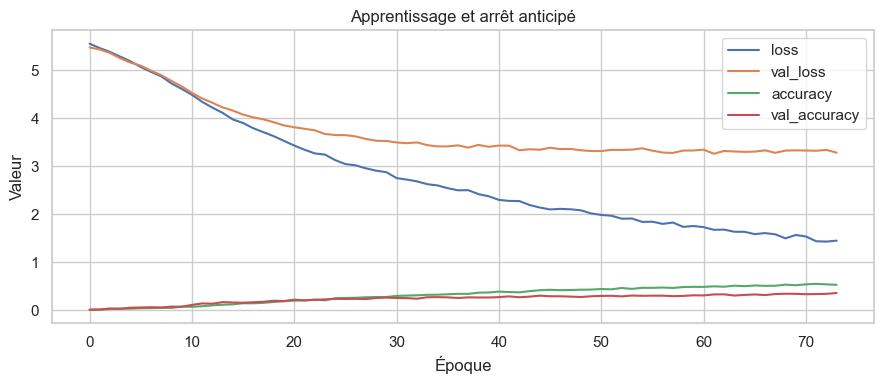

In [6]:
def build_cnn(input_features: int, n_classes: int) -> tf.keras.Model:
    """Build an experimental 1D CNN for the selected tabular columns."""
    model = tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(input_features, 1)),
            tf.keras.layers.Conv1D(32, kernel_size=5, padding="same", activation="relu"),
            tf.keras.layers.MaxPooling1D(pool_size=2),
            tf.keras.layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"),
            tf.keras.layers.GlobalMaxPooling1D(),
            tf.keras.layers.Dense(128, activation="relu"),
            tf.keras.layers.Dropout(0.35),
            tf.keras.layers.Dense(n_classes, activation="softmax"),
        ]
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

classes_in_fit = np.unique(y_fit)
weights = compute_class_weight(class_weight="balanced", classes=classes_in_fit, y=y_fit)
class_weights = {int(label): float(weight) for label, weight in zip(classes_in_fit, weights)}

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
model = build_cnn(n_features, len(label_encoder.classes_))
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=12, restore_best_weights=True
)
history = model.fit(
    X_fit_cnn,
    y_fit,
    validation_data=(X_stop_cnn, y_stop),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1,
)
best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print("Meilleure époque selon val_loss:", best_epoch)

pd.DataFrame(history.history)[["loss", "val_loss", "accuracy", "val_accuracy"]].plot(figsize=(9, 4))
plt.title("Apprentissage et arrêt anticipé")
plt.xlabel("Époque")
plt.ylabel("Valeur")
plt.tight_layout()
plt.show()

## 7. Évaluation sur la validation interne — tableau des métriques

La moyenne **macro** donne le même poids à chaque utilisateur; la moyenne **pondérée** tient compte de leur effectif. L'accuracy est ajoutée pour compléter les métriques demandées. Ces résultats concernent seulement la validation extraite du train, jamais le test sans étiquettes.

,Modèle,Jeu évalué,Precision_macro,Recall_macro,F1_macro,Precision_pondérée,Recall_pondéré,F1_pondéré,Accuracy
0,CNN 1D,validation interne de train,0.3338,0.3491,0.3125,0.4008,0.3765,0.3595,0.3765


Interprétation: macro = utilisateurs traités équitablement; pondéré = pondération par nombre de sessions.
Le score test n'est pas calculable sans les vraies étiquettes du test.


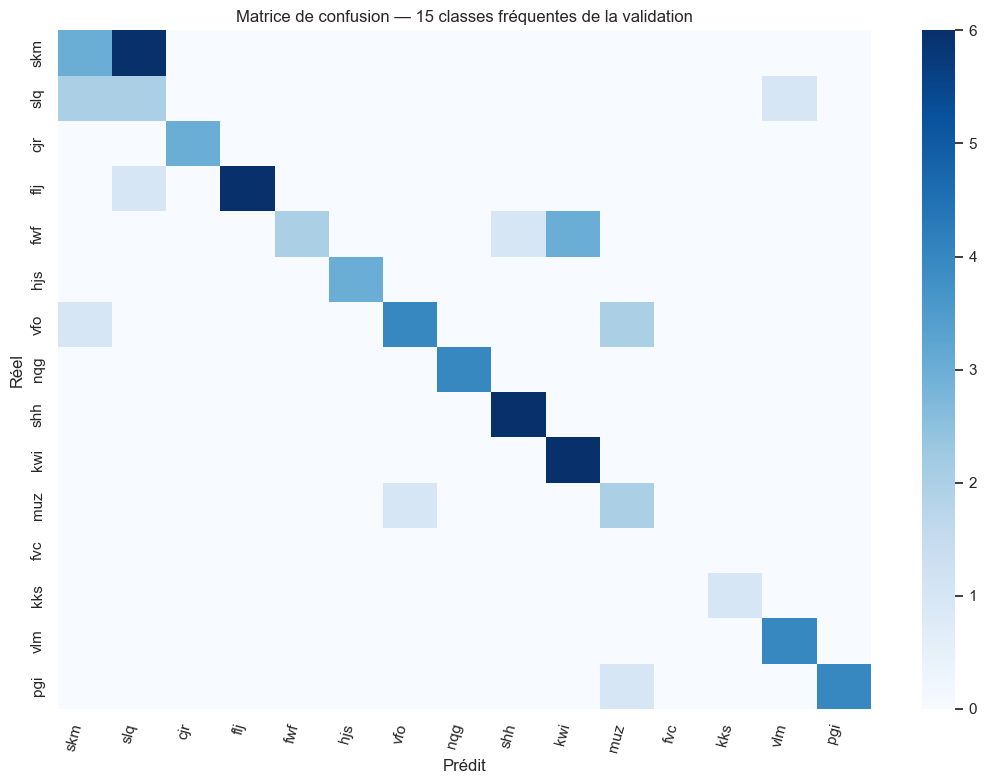

In [7]:
eval_probabilities = model.predict(X_eval_cnn, verbose=0)
y_eval_pred = eval_probabilities.argmax(axis=1)

p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
    y_eval, y_eval_pred, average="macro", zero_division=0
)
p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_eval, y_eval_pred, average="weighted", zero_division=0
)
metrics_table = pd.DataFrame(
    [
        {
            "Modèle": "CNN 1D",
            "Jeu évalué": "validation interne de train",
            "Precision_macro": p_macro,
            "Recall_macro": r_macro,
            "F1_macro": f1_macro,
            "Precision_pondérée": p_weighted,
            "Recall_pondéré": r_weighted,
            "F1_pondéré": f1_weighted,
            "Accuracy": accuracy_score(y_eval, y_eval_pred),
        }
    ]
)
display(metrics_table.round(4))

print("Interprétation: macro = utilisateurs traités équitablement; pondéré = pondération par nombre de sessions.")
print("Le score test n'est pas calculable sans les vraies étiquettes du test.")

# Matrice de confusion lisible pour les 15 classes les plus fréquentes dans la validation.
top_eval_labels = pd.Series(y_eval).value_counts().head(15).index.to_numpy()
cm = confusion_matrix(y_eval, y_eval_pred, labels=top_eval_labels)
top_eval_names = label_encoder.inverse_transform(top_eval_labels)
plt.figure(figsize=(11, 8))
sns.heatmap(cm, cmap="Blues", xticklabels=top_eval_names, yticklabels=top_eval_names)
plt.title("Matrice de confusion — 15 classes fréquentes de la validation")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 8. Réentraîner sur tout le train et prédire le test

Après l'évaluation, la sélection et la standardisation sont recalculées sur tout `cleaned_train.csv`. Un nouveau CNN est entraîné pendant le nombre d'époques choisi sur l'ensemble de développement, puis appliqué au test. La sortie conserve le format de soumission `RowId,prediction`; aucun score test n'est affiché car les vérités terrain sont absentes.

In [8]:
final_variance_filter = VarianceThreshold(threshold=0.0)
X_full_var = final_variance_filter.fit_transform(X_all_df)
X_test_full_var = final_variance_filter.transform(X_test_df)
final_nonconstant_names = X_all_df.columns[final_variance_filter.get_support()]

final_selector = SelectKBest(score_func=safe_f_classif, k=min(TOP_K, len(final_nonconstant_names)))
X_full_selected = final_selector.fit_transform(X_full_var, label_encoder.transform(y_text))
X_test_selected = final_selector.transform(X_test_full_var)
final_selected_names = final_nonconstant_names[final_selector.get_support()]

final_scaler = StandardScaler()
X_full_scaled = final_scaler.fit_transform(X_full_selected).astype(np.float32)
X_test_scaled = final_scaler.transform(X_test_selected).astype(np.float32)
X_full_cnn = as_cnn_input(X_full_scaled)
X_test_cnn = as_cnn_input(X_test_scaled)
y_full = label_encoder.transform(y_text)

all_classes = np.unique(y_full)
all_weights = compute_class_weight(class_weight="balanced", classes=all_classes, y=y_full)
final_class_weights = {int(label): float(weight) for label, weight in zip(all_classes, all_weights)}

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
final_model = build_cnn(X_full_scaled.shape[1], len(label_encoder.classes_))
final_model.fit(
    X_full_cnn,
    y_full,
    epochs=best_epoch,
    batch_size=BATCH_SIZE,
    class_weight=final_class_weights,
    verbose=1,
)

test_probabilities = final_model.predict(X_test_cnn, verbose=0)
test_predicted_ids = test_probabilities.argmax(axis=1)
test_predictions = label_encoder.inverse_transform(test_predicted_ids)
submission = pd.DataFrame(
    {"RowId": np.arange(1, len(test_predictions) + 1), "prediction": test_predictions}
)
submission_path = DATA_DIR / "700_cnn_submission.csv"
submission.to_csv(submission_path, index=False)

assert len(submission) == len(test_df), "Le nombre de prédictions doit égaler le nombre de lignes test."
assert submission["RowId"].tolist() == list(range(1, len(test_df) + 1))
assert set(submission["prediction"]).issubset(set(label_encoder.classes_))
print("Variables sélectionnées pour le modèle final:", len(final_selected_names))
print("Prédictions générées:", len(submission))
print("Fichier créé:", submission_path)
display(submission.head(10))

Epoch 1/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0031 - loss: 5.5606 
Epoch 2/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0211 - loss: 5.4536
Epoch 3/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0283 - loss: 5.3564
Epoch 4/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0412 - loss: 5.2490
Epoch 5/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0437 - loss: 5.1226
Epoch 6/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0495 - loss: 4.9929
Epoch 7/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0567 - loss: 4.7875
Epoch 8/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0661 - loss: 4.5624
Epoch 9/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0866 - loss: 4.3564
Epoch 10/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0954 - loss: 4.1921
Epoch 11/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1091 - loss: 4.0561
Epoch 12/62
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1111 - l

,RowId,prediction
0,1,hzx
1,2,iib
2,3,jmq
3,4,psg
4,5,cvw
5,6,wem
6,7,uwp
7,8,cnh
8,9,nfh
9,10,gor


## 9. Conclusion et limites

- Le tableau final des métriques mesure le CNN sur une validation interne du train, pas sur le test Kaggle.
- Les classes sont très déséquilibrées et certaines n'ont que quelques sessions; leurs scores individuels sont donc très incertains. Comparer F1 macro et pondéré aide à voir cet effet.
- Le classement ANOVA mesure une association univariée avec la cible; il ne prouve pas qu'une caractéristique cause l'identité et peut manquer des interactions.
- Un CNN 1D suppose que des colonnes voisines ont une structure locale. Ici, l'ordre des colonnes est surtout un rangement par familles; cette expérience doit être comparée ultérieurement à un MLP ou à un modèle d'arbres sur les mêmes séparations.
- Pour calculer des métriques sur le véritable test, il faudrait obtenir les étiquettes `util` correspondantes. En leur absence, le notebook produit uniquement les prédictions et le fichier de soumission.